# 5장 1강: 일반화와 학습 안정화 기법 — 실습문제

## 실습 목표

- 학습 손실과 검증 손실을 함께 보고 과적합의 징후를 설명합니다.
- Dropout과 Weight Decay가 각각 무엇을 바꾸는지 계산합니다.
- Batch Normalization의 학습·평가 시 동작 차이를 이해합니다.
- Early Stopping의 중단 시점과 최적 가중치 복원 시점을 구분합니다.

## 실습 환경 / 데이터

- Python, pandas, NumPy, Matplotlib을 사용합니다. 별도의 딥러닝 프레임워크는 필요하지 않습니다.
- **`concrete_data.csv`**를 노트북과 같은 폴더에 두고 실행하세요. 파일 이름이 `concrete_data(1).csv`인 경우에도 준비 코드가 읽을 수 있습니다.
- 원본은 1,030행, 9열이며 8개 입력 특성과 실제 압축강도 `concrete_compressive_strength`로 구성됩니다.
- 동일한 전체 행이 학습·검증에 중복으로 들어가는 것을 줄이기 위해 완전히 같은 25행을 제거합니다. 남은 1,005행을 고정된 난수 순서로 섞어 **학습 80행, 검증 200행**을 사용합니다. 나머지 725행은 이번 실습에서 사용하지 않습니다.
- 작은 학습 표본은 빠르게 학습 기록을 만들고 일반화 차이를 관찰하기 위한 교육용 설정입니다. 이 표본 수를 실제 프로젝트의 권장 비율로 제시하는 것은 아닙니다.
- 입력과 목표의 평균·표준편차는 **학습 80행에서만** 구하고 검증에도 같은 값을 적용합니다. 표준화와 학습 함수는 제공 코드이므로 새로 작성할 필요가 없습니다.
- 순서대로 셀을 실행하세요. 결과 표의 마지막 소수 자리는 실행 환경에 따라 조금 달라질 수 있습니다.

## 이번 강의의 범위

제공된 **5장 1강 목차: 과적합과 일반화, Dropout, Weight Decay, Batch Normalization, Early Stopping**을 기준으로 구성했습니다. 강의 본문은 별도로 제공되지 않았으므로 모델 크기·마스크·가중치·설정값은 원리를 확인하기 위해 정한 예시입니다.

**학습 상태 진단에는 Concrete 데이터로 실제 계산한 손실 기록**을 사용합니다. 데이터 준비·학습·중단 판단 함수는 제공하고, 학생은 호출·간단한 계산·해석을 수행합니다. 역전파 유도, 전체 학습 코드 구현, 최적 설정 탐색은 요구하지 않습니다.

Dropout·Weight Decay·Batch Normalization은 각각 작은 계산으로 동작을 확인합니다. 이 계산들이 진단용 모델의 학습에 적용된 것은 아니므로, 각 기법을 사용한 뒤 검증 성능이 좋아졌다고 주장하지 않습니다. 별도의 테스트 성능 평가도 수행하지 않습니다.

## 실습 구성

| 구분 | 문제 | 할 일 |
|---|---|---|
| 실습 1 | 1-1 | 실제 학습·검증 손실로 학습 상태 진단 |
| 실습 1 | 1-2 | Dropout과 Weight Decay의 계산 비교 |
| 실습 2 | 2-1 | Batch Normalization의 학습·평가 계산 |
| 실습 2 | 2-2 | Early Stopping 판단과 최적 가중치 복원 |
| 기초 과제 | 3-1 | 기다리는 횟수를 바꾸고 네 기법의 역할 정리 |

**실습 2개 + 기초 과제 1개**이며 세부 문항 수는 내용에 맞추어 구성했습니다.

## 시작 전에 읽을 용어

| 용어 | 쉽게 풀어쓴 뜻 |
|---|---|
| 일반화 | 학습에 쓰지 않은 새로운 데이터에도 예측이 잘 맞는 성질 |
| 과적합 | 학습 데이터에 지나치게 맞추어 새로운 데이터에 대한 성능이 충분히 좋아지지 않거나 나빠지는 상태 |
| 학습 데이터 | 가중치를 업데이트할 때 사용하는 데이터 |
| 검증 데이터 | 업데이트에 직접 사용하지 않고 학습 상태·설정을 판단하는 데이터 |
| Epoch | 학습 데이터를 한 차례 사용한 횟수. 이번 코드는 80행 전체로 한 번 업데이트 |
| MSE | 예측 오차를 제곱하여 평균한 손실. 작을수록 예측 오차가 작음 |
| Dropout | 학습 중 일부 활성값을 임시로 0으로 만드는 방식 |
| Weight Decay | 업데이트 때 가중치를 0 방향으로 줄이는 항을 추가하는 방식 |
| Batch | 함께 처리하는 여러 샘플의 묶음 |
| Batch Normalization, BN | 학습 중 배치의 특성별 통계로 값을 정규화하고 크기·위치를 조절하는 층 |
| gamma·beta | BN 결과의 크기와 위치를 조절하는 학습 가능한 값 |
| running mean·variance | 평가 때 사용할 수 있도록 학습 중 누적해 두는 평균·분산 |
| Early Stopping | 검증 성능이 정해진 기간 동안 개선되지 않으면 학습을 멈추는 규칙 |
| patience | 개선이 없을 때 기다릴 연속 횟수 |
| checkpoint | 특정 시점의 가중치·편향을 저장한 값 |

검증 결과로 시점이나 설정을 골랐다면 그 검증 데이터는 선택 과정에 관여한 것입니다. 새로운 데이터에서의 최종 성능은 별도로 남겨 둔 테스트 데이터로 확인해야 합니다.

### 처음 배우는 학생을 위한 출발점

Concrete 데이터의 한 행은 콘크리트 한 샘플의 재료·조건과 실제 압축강도를 담고 있습니다. 모델은 재료·조건을 입력받아 압축강도를 예측합니다. **이미 배운 샘플에 잘 맞추는 것과 처음 보는 샘플에도 잘 맞추는 것은 다릅니다.** 일반화는 두 번째 능력입니다. 연습문제의 답만 외우면 새 문제를 풀기 어려운 것처럼, 학습 데이터에만 지나치게 맞춘 모델은 새 데이터에서 오차가 커질 수 있습니다.

가중치·편향을 고치는 과정을 **학습**, 현재 가중치로 답을 계산하는 과정을 **예측**이라고 합니다. 예측값과 실제값의 차이를 숫자 하나로 요약한 것이 **손실(Loss)**입니다. 이번 손실은 작을수록 좋습니다. ‘학습 안정화’는 가중치를 조정하는 과정이 원활하게 진행되도록 돕는다는 뜻이고, ‘일반화 개선’은 새 데이터에 대한 성능이 좋아진다는 뜻입니다. 두 목적은 연결되지만 같은 말은 아닙니다.

| 데이터 구분 | 이번 자료에서 하는 일 | 가중치 계산에 사용하는가요? |
|---|---|---|
| 학습 80행 | 예측 오차로 가중치·편향 업데이트 | 예 |
| 검증 200행 | 학습 상태와 중단 시점 판단 | 기울기 업데이트에는 사용하지 않음. 모델 선택에는 관여함 |
| 미사용 725행 | 이번 실습에서 사용하지 않음 | 아니요. 이 자료에서 테스트 평가를 수행한 것은 아님 |

### MSE를 숫자로 이해하기

MSE는 ‘Mean Squared Error’의 줄임말로 **평균 제곱 오차**입니다. 계산 순서는 ① 예측값에서 실제값을 빼고 ② 각 차이를 제곱하고 ③ 모두 더한 뒤 샘플 수로 나누기입니다.

계산법만 보기 위한 예로, 표준화된 실제값 두 개가 `[0, 1]`, 예측값이 `[0.2, 0.6]`이라면 다음과 같습니다. 실제 학습 결과가 아닌 작은 설명용 예시입니다.

| 단계 | 계산 |
|---|---|
| 예측 − 실제 | `[0.2−0, 0.6−1] = [0.2, −0.4]` |
| 제곱 | `[0.2×0.2, (−0.4)×(−0.4)] = [0.04, 0.16]` |
| 평균 | `(0.04+0.16)/2 = 0.10` |

음수 오차도 제곱하면 양수가 되므로, 너무 높게 예측한 오차와 너무 낮게 예측한 오차가 서로 지워지지 않습니다. 코드의 `**2`는 제곱, `np.mean(...)`은 평균입니다. 수식에서 Σ(시그마)는 해당 값들을 ‘모두 더하라’는 기호입니다. 이번에는 목표 압축강도를 표준화한 뒤 손실을 계산하므로 MSE 숫자를 압축강도의 원래 단위인 MPa로 바로 읽지 않습니다.


### 주제별 학습 위치

| 강의 주제 | 문제 | 확인할 핵심 |
|---|---|---|
| 과적합과 일반화 | 실습 1-1 | 학습·검증 손실을 함께 읽는 이유, 과적합 징후와 판단의 한계 |
| Dropout | 실습 1-2, 과제 3-1 | 활성값 임시 제거, 유지값 보정, 평가 시 동작 |
| Weight Decay | 실습 1-2, 과제 3-1 | 가중치를 0 방향으로 당기는 항과 데이터 기울기의 차이 |
| Batch Normalization | 실습 2-1, 과제 3-1 | 열별 평균·분산, gamma·beta, 학습·평가 통계의 차이 |
| Early Stopping | 실습 2-2, 과제 3-1 | patience, 중단 시점과 최적 가중치 복원 시점의 차이 |

과제는 실습에서 사용한 함수의 기다리는 횟수만 바꾸고 결과를 비교하는 필수 수준의 복습입니다. 새로운 모델 구현이나 심화 수식 유도는 요구하지 않습니다.


**실행 순서:** 준비 네 셀 → 실습 1-1 → 실습 1-2 → 실습 2-1 → 실습 2-2 → 과제입니다. 변수 이름을 찾을 수 없다는 `NameError`가 나오면 앞 셀을 실행했는지 확인하세요. CSV를 찾을 수 없다는 오류가 나오면 데이터 파일 이름과 실행 폴더를 확인하세요. 설치한 pandas·NumPy·Matplotlib을 사용할 수 있는 Python 커널을 선택합니다.

### 이번 자료에는 두 가지 계산 흐름이 있습니다

| 흐름 | 입력과 구조 | 확인할 내용 |
|---|---|---|
| 실제 학습 기록 | Concrete 입력 8개 → Tanh 뉴런 32개 → 출력 1개 | 학습·검증 손실, Early Stopping, 최적 가중치 복원 |
| 작은 동작 예제 | 학습 샘플 4개의 시멘트·물 → 고정 가중치의 뉴런 3개 | Dropout의 활성값, Weight Decay의 가중치, BN의 통계와 변환 |

작은 동작 예제에서 기법을 계산했다고 실제 학습 모델에 그 기법을 적용한 것은 아닙니다. 두 흐름을 구분해야 ‘기법을 켜서 성능이 개선됐다’는 잘못된 해석을 피할 수 있습니다. 작은 예제의 Dropout과 BN도 이어 붙인 계산이 아닙니다. Dropout은 H에서, BN은 원래 Z에서 각각 출발합니다.


## 실습 준비 — 제공 코드 네 셀을 그대로 실행하세요

### 진단용 학습 함수

입력 8개 → Tanh 은닉 뉴런 32개 → 압축강도 출력 1개의 작은 신경망입니다. 제공 함수 `train_demo()`는 기본 경사하강법, 학습률 0.03으로 1,200 epoch를 실행하고 손실 기록과 각 epoch의 가중치 사본을 반환합니다. 함수 내부는 앞 강의의 순전파·역전파·업데이트를 묶은 보조 코드입니다. 작성하거나 외우는 문제는 아닙니다.

목표 압축강도도 학습 평균·표준편차로 바꾸었으므로 손실은 **표준화된 목표의 MSE**입니다. MPa 단위의 오차나 정확도가 아닙니다. 매 epoch 업데이트가 끝난 뒤 같은 시점의 파라미터로 학습·검증 손실을 계산합니다. 검증값으로 기울기를 업데이트하지 않습니다.

### 동작 계산용 작은 층

학습 데이터의 앞 4개 샘플에서 시멘트·물을 각각 100으로 나눈 값 U를 사용합니다. 고정 W·b로 `Z=U@W+b`, `H=ReLU(Z)`를 만듭니다. 이는 Dropout과 BN의 숫자를 보기 위한 **별도 작은 계산 예시**이며, 진단용 8→32→1 모델과 구분합니다.

### Early Stopping 제공 함수

`replay_early_stopping(history, checkpoints, patience)`는 기록을 처음부터 시간 순서대로 확인합니다. 규칙은 다음과 같습니다.

1. 현재 검증 손실이 지금까지의 최저값보다 **엄격히 작으면** 개선입니다. 최소 개선 폭은 0이며 같은 값은 개선이 아닙니다.
2. 개선하면 최적 가중치를 저장하고 기다린 횟수를 0으로 만듭니다.
3. 개선하지 않으면 기다린 횟수를 1 늘립니다.
4. 기다린 횟수가 patience에 도달하면 중단합니다.

반환값은 판단 요약, 판단 기록, 복원할 최적 파라미터입니다. 완성된 1,200 epoch 기록을 비교하기 위해 먼저 학습하고 중단 규칙을 **재생**합니다. 실제 학습을 조기에 끝내려면 같은 판단을 학습 반복문 안에 넣어야 합니다. 이번 재생이 이미 수행한 학습 시간을 줄여 주는 것은 아닙니다.

### 계산에 등장하는 이름과 기호

| 기호·코드 | 쉬운 뜻 |
|---|---|
| U | 시멘트·물 두 입력을 담은 4행·2열 배열 |
| W, b | 입력에 곱하는 가중치, 곱한 결과에 더하는 편향 |
| Z = U @ W + b | 가중치를 곱하고 편향을 더한 중간 결과. 4행·3열 |
| H = ReLU(Z) | Z의 음수를 0으로 바꾼 활성값. 활성값은 뉴런이 다음 계산에 전달하는 숫자 |
| mask, p | 남길 자리를 표시한 0·1 배열, 제거 확률 |
| G, lr, λ(람다) | 가중치 기울기, 학습률, Weight Decay의 강도 |
| μ(뮤), v | 평균, 분산. BN에서는 뉴런별로 구함 |
| √, ε(엡실론) | 제곱근 기호, 분모에 더하는 아주 작은 양수 |
| γ(감마), β(베타) | 정규화한 값에 곱할 크기 조절값, 더할 위치 조절값 |
| wait, best_epoch | 연속으로 개선하지 못한 횟수, 지금까지 검증 손실이 가장 낮았던 epoch |

`@`는 행렬곱입니다. 왼쪽 배열의 한 행과 오른쪽 배열의 한 열에서 대응하는 숫자를 곱해 더합니다. 반면 `H * mask`의 `*`는 같은 위치끼리 곱합니다. 이 둘은 다른 계산입니다. `Z[:1]`은 Z의 첫 행을 1행·3열 배열로 가져오고, `axis=0`은 여러 행에 걸쳐 같은 열의 값을 모아 계산하라는 뜻입니다.

**평균**은 합을 개수로 나눈 값입니다. **분산**은 각 값이 평균에서 얼마나 떨어졌는지 제곱하여 평균한 값입니다. **표준편차**는 분산의 제곱근입니다. 예를 들어 `[1, 3]`의 평균은 2, 분산은 `((1−2)²+(3−2)²)/2=1`, 표준편차는 √1=1입니다. 표준화는 ‘평균을 빼고 표준편차로 나누기’입니다. BN에서는 분모의 안정성을 위해 분산에 ε을 더한 뒤 제곱근을 구합니다.

`1e-5`는 `0.00001`입니다. 출력의 `−2.2e-16`처럼 매우 작은 숫자는 계산 과정의 소수점 표현 오차로 0에 아주 가까운 값일 수 있습니다. 출력 표시는 반올림되지만 실제 계산과 Early Stopping 비교에는 반올림하기 전의 숫자를 사용합니다.

### 학습 모드·평가 모드와 데이터 구분

학습/검증은 **데이터를 쓰는 목적**, 학습 모드/평가 모드는 **층이 동작하는 방식**을 가리킵니다. 일반적으로 검증·새 데이터 예측에는 평가 모드를 사용하여 Dropout의 무작위 제거를 끄고 BN의 저장 통계를 사용합니다. 평가 모드로 바꾼다고 이미 배운 가중치가 사라지는 것은 아닙니다.

이 노트북은 NumPy로 두 동작을 따로 계산합니다. 따라서 별도의 모드 전환 명령을 입력하는 문제가 아닙니다. 진단용 학습 모델에는 Dropout·Weight Decay·BN을 적용하지 않았고, 세 기법은 별도 작은 층에서 원리만 살펴봅니다.

### 실행 순서와 학습 횟수

먼저 준비 코드 네 셀을 실행한 뒤 실습 1, 실습 2, 과제 순으로 진행합니다. 실습 2-2와 과제는 실습 1-1에서 만든 `history`와 `checkpoints`를 사용합니다. `history`에는 매 epoch의 손실 숫자, `checkpoints`에는 해당 epoch의 가중치·편향 배열 사본이 들어 있습니다.

일반적으로 1 epoch는 전체 학습 데이터를 한 번 사용한 것입니다. 데이터를 여러 배치로 나누면 한 epoch 안에서 여러 번 업데이트할 수 있습니다. 이번 제공 함수는 80행 전체를 한 배치로 사용하므로 **1 epoch당 업데이트가 한 번**입니다. 이 관계가 모든 학습 코드에 똑같이 적용되는 것은 아닙니다.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = Path("concrete_data.csv")
if not data_path.exists():
    data_path = Path("concrete_data(1).csv")
original = pd.read_csv(data_path)
original.columns = original.columns.str.strip()
df = original.drop_duplicates().reset_index(drop=True)
target = "concrete_compressive_strength"
features = [name for name in df.columns if name != target]
# 난수 시드를 고정하여 같은 분리를 재현합니다.
indices = np.random.default_rng(42).permutation(len(df))
train_df = df.iloc[indices[:80]].copy()
valid_df = df.iloc[indices[80:280]].copy()

train_raw = train_df[features].to_numpy(dtype=float)
valid_raw = valid_df[features].to_numpy(dtype=float)
# 전처리 기준은 학습 데이터에서만 구합니다.
x_mean = train_raw.mean(axis=0)
x_std = train_raw.std(axis=0)
X_train = (train_raw - x_mean) / x_std
# 검증에도 학습에서 구한 동일한 기준을 적용합니다.
X_valid = (valid_raw - x_mean) / x_std
# 목표도 학습 기준으로 표준화하므로 손실은 MPa 단위가 아닙니다.
y_raw = train_df[[target]].to_numpy(dtype=float)
y_valid_raw = valid_df[[target]].to_numpy(dtype=float)
y_mean = y_raw.mean()
y_std = y_raw.std()
y_train = (y_raw - y_mean) / y_std
y_valid = (y_valid_raw - y_mean) / y_std

print("원본 / 중복 제거 후:", original.shape, df.shape)
print("결측값 수:", df.isna().sum().sum())
print("학습 / 검증 / 미사용 행:", len(train_df), len(valid_df), len(df)-280)
print("입력 / 목표 크기:", X_train.shape, y_train.shape)


원본 / 중복 제거 후: (1030, 9) (1005, 9)
결측값 수: 0
학습 / 검증 / 미사용 행: 80 200 725
입력 / 목표 크기: (80, 8) (80, 1)


In [2]:
def predict(values, params):
    w1, b1, w2, b2 = params
    return np.tanh(values @ w1 + b1) @ w2 + b2


def train_demo():
    rng = np.random.default_rng(7)
    w1 = rng.normal(0.0, 0.3, size=(8, 32))
    b1 = np.zeros((1, 32))
    w2 = rng.normal(0.0, 0.1, size=(32, 1))
    b2 = np.zeros((1, 1))
    records, checkpoints = [], []
    for epoch in range(1, 1201):
        # 1. 현재 파라미터로 학습 입력을 순전파합니다.
        hidden = np.tanh(X_train @ w1 + b1)
        prediction = hidden @ w2 + b2
        # 2. 학습 데이터 오차로 모든 파라미터의 기울기를 구합니다.
        grad_output = 2.0 * (prediction - y_train) / len(X_train)
        grad_w2 = hidden.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        grad_hidden = (grad_output @ w2.T) * (1.0 - hidden**2)
        grad_w1 = X_train.T @ grad_hidden
        grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
        # 3. 모든 기울기를 구한 다음 업데이트합니다.
        w1 -= 0.03 * grad_w1
        b1 -= 0.03 * grad_b1
        w2 -= 0.03 * grad_w2
        b2 -= 0.03 * grad_b2
        # 4. 업데이트 뒤 같은 파라미터로 두 손실을 기록합니다.
        params = (w1, b1, w2, b2)
        train_loss = np.mean((predict(X_train, params) - y_train)**2)
        valid_loss = np.mean((predict(X_valid, params) - y_valid)**2)
        records.append({"epoch": epoch, "train_loss": train_loss, "valid_loss": valid_loss})
        # 배열의 사본을 저장하여 이후 업데이트와 분리합니다.
        checkpoints.append(tuple(value.copy() for value in params))
    return pd.DataFrame(records), checkpoints


print("학습·예측 함수 준비 완료")


학습·예측 함수 준비 완료


In [3]:
# 진단용 학습 모델과 별도의 작은 동작 계산 예제입니다.
U = train_df[["cement", "water"]].iloc[:4].to_numpy(dtype=float) / 100.0
W = np.array([[1.0, 0.5, -0.5], [0.5, -1.0, 1.0]])
b = np.array([0.0, 1.0, 2.0])
# 가중합은 BN에, ReLU 활성값은 Dropout에 따로 사용합니다.
Z = U @ W + b
H = np.maximum(0.0, Z)

# 계산을 따라가기 위한 고정 마스크: 1은 유지, 0은 제거입니다.
mask = np.array([[1, 0, 1], [0, 1, 0], [1, 1, 0], [0, 0, 1]])
print("계산용 U:", U)
print("가중합 Z:", np.round(Z, 6))
print("ReLU 활성값 H:", np.round(H, 6))


계산용 U: [[1.02  1.92 ]
 [2.    1.92 ]
 [2.149 1.556]
 [2.772 1.607]]
가중합 Z: [[ 1.98   -0.41    3.41  ]
 [ 2.96    0.08    2.92  ]
 [ 2.927   0.5185  2.4815]
 [ 3.5755  0.779   2.221 ]]
ReLU 활성값 H: [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]


In [4]:
def replay_early_stopping(history, checkpoints, patience):
    best_loss = float("inf")
    best_epoch = None
    best_params = None
    wait = 0
    trace = []
    stopped = False
    for row in history.itertuples(index=False):
        # 직전 손실이 아니라 지금까지의 최저와 비교합니다.
        improved = row.valid_loss < best_loss
        if improved:
            best_loss = row.valid_loss
            best_epoch = int(row.epoch)
            # epoch는 1부터, 체크포인트 목록 위치는 0부터 시작합니다.
            best_params = tuple(p.copy() for p in checkpoints[best_epoch - 1])
            wait = 0
        else:
            wait += 1
        trace.append({"epoch": int(row.epoch), "valid_loss": row.valid_loss,
                      "improved": improved, "wait": wait, "best_epoch": best_epoch})
        # 연속 비개선 횟수가 한도에 도달하면 이후 기록을 읽지 않습니다.
        if wait >= patience:
            stopped = True
            break
    result = {"stopped": stopped, "last_checked_epoch": trace[-1]["epoch"],
              "best_epoch": best_epoch, "best_valid_loss": best_loss}
    return result, pd.DataFrame(trace), best_params


print("Early Stopping 판단 함수 준비 완료")


Early Stopping 판단 함수 준비 완료


---

## 실습 1. 일반화와 과적합 억제


### 문제 1-1. 학습·검증 손실 함께 읽기

#### 문제 설명

제공 함수로 실제 학습 기록을 만들고, 학습이 진행될 때 학습 손실과 검증 손실이 어떻게 달라지는지 확인하세요.

#### 요구사항

1. `history,checkpoints=train_demo()`를 실행하세요.
2. 1·100·200·400·600·800·1000·1200 epoch의 기록을 출력하세요.
3. `history["valid_loss"].idxmin()`으로 검증 손실 최저 행을 찾으세요.
4. 학습·검증 손실을 그래프로 확인하세요. 그래프 코드는 작성 도움말을 참고해도 됩니다.

#### 작성 도움말

`history[history["epoch"].isin([1,100,200,400,600,800,1000,1200])]`으로 행을 고릅니다. `plt.plot(history["epoch"],history["train_loss"],label="Train")`와 같은 방법으로 검증 곡선도 그립니다. 첫 행 번호가 0이므로 DataFrame 행 번호와 epoch를 구분하세요.

#### 해석 질문

**Q1.** 일반화와 과적합은 무엇인가요? 검증 손실까지 함께 봐야 하는 이유는 무엇인가요?

**Q2.** 검증 손실이 가장 작은 epoch와 그 값은 무엇인가요? 최저점 이후와 마지막 기록을 비교해 어떤 징후를 읽을 수 있나요?

**Q3.** 학습 손실보다 검증 손실이 높으면 언제나 심한 과적합인가요? 이번 검증 최저값을 최종 테스트 성능으로 발표해도 되나요?

#### 제출 결과

주요 손실 표·그래프, 검증 최저 행, Q1~Q3 답변.


 epoch  train_loss  valid_loss
     1    1.309837    1.658692
   100    0.221291    0.467928
   200    0.187021    0.428178
   400    0.145534    0.399101
   600    0.122144    0.395813
   800    0.107144    0.396244
  1000    0.095320    0.396382
  1200    0.084271    0.397232
검증 최저 행: {'epoch': 584.0, 'train_loss': 0.12361734973016873, 'valid_loss': 0.3958047137386123}


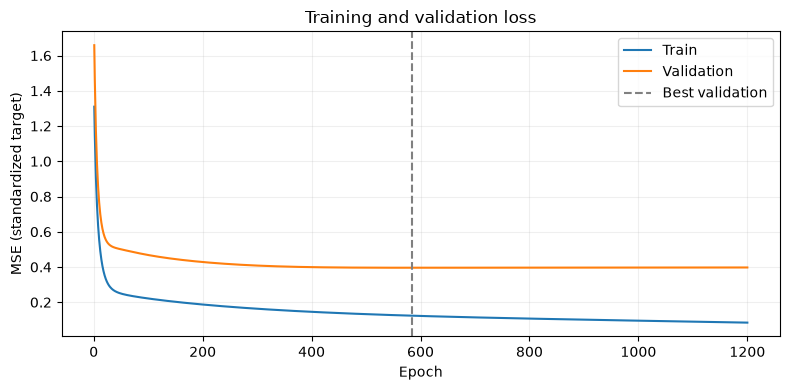

In [5]:
# history, checkpoints = train_demo()
# selected = history[history["epoch"].isin([1,100,200,400,600,800,1000,1200])]
# print(selected)
# best_row = ...

# 학습·검증 손실을 그리고 결과를 해석하세요.

history, checkpoints = train_demo()
selected = history[history['epoch'].isin([1,100,200,400,600,800,1000,1200])]
best_row = history.loc[history['valid_loss'].idxmin()]
print(selected.round(9).to_string(index=False))
print('검증 최저 행:', best_row.to_dict())
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(history['epoch'],history['train_loss'],label='Train')
ax.plot(history['epoch'],history['valid_loss'],label='Validation')
ax.axvline(best_row['epoch'],color='gray',linestyle='--',label='Best validation')
ax.set(xlabel='Epoch',ylabel='MSE (standardized target)',title='Training and validation loss')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: 주요 시점 표는 다음과 같다.

| epoch | train_loss | valid_loss |
| --- | --- | --- |
| 1 | 1.3098373 | 1.65869152 |
| 100 | 0.221290716 | 0.467928246 |
| 200 | 0.187020566 | 0.42817777 |
| 400 | 0.145533728 | 0.399101442 |
| 600 | 0.122144287 | 0.39581305 |
| 800 | 0.107143541 | 0.39624352 |
| 1000 | 0.0953197093 | 0.396382099 |
| 1200 | 0.0842713355 | 0.397232468 |
검증 최저: epoch 584: 학습 0.12361735, 검증 0.395804714
- 첫 값의 대입 과정 또는 판단 근거: epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 악화 폭은 0.00142775393 (최저 대비 약 0.360721812%)이다. 학습 손실은 계속 내려가지만 검증은 최저점 이후 소폭 올라간다.

**Q1. 일반화와 과적합은 무엇인가요? 검증 손실까지 함께 봐야 하는 이유는 무엇인가요?**

- 내 답변: 일반화는 새 데이터에 잘 맞는 성질이고 과적합은 학습에 지나치게 맞춰 새 데이터 성능이 충분히 개선되지 않거나 나빠지는 상태이다. 학습 손실만으로 새로운 데이터의 오차를 알 수 없어 검증도 함께 본다.
- 수치 또는 코드에 근거한 이유: 가중치 업데이트는 학습 80행에서만 하고 검증 200행은 별도로 손실을 계산한다. 두 손실의 시간 추세를 함께 비교해야 한다.

**Q2. 검증 손실이 가장 작은 epoch와 그 값은 무엇인가요? 최저점 이후와 마지막 기록을 비교해 어떤 징후를 읽을 수 있나요?**

- 내 답변: 검증 최저 epoch는 584, 값은 0.395804714이다. 이후 학습은 개선되지만 검증이 소폭 악화해 과적합 징후가 있다.
- 수치 또는 코드에 근거한 이유: epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 악화 폭은 0.00142775393 (최저 대비 약 0.360721812%)이다.

**Q3. 학습 손실보다 검증 손실이 높으면 언제나 심한 과적합인가요? 이번 검증 최저값을 최종 테스트 성능으로 발표해도 되나요?**

- 내 답변: 아니다. 데이터 난이도·표본 수 차이 등으로도 격차가 생길 수 있다. 이번 검증 결과는 모델 선택에 사용했으므로 별도 테스트 성능으로 발표할 수 없다.
- 수치 또는 코드에 근거한 이유: 이번 악화 폭은 작아 심한 과적합으로 과장하지 않는다. 미사용 725행에 대한 테스트 평가는 수행하지 않았다.


### 문제 1-2. Dropout과 Weight Decay는 무엇을 바꿀까요?

#### 문제 설명

두 기법의 동작을 따로 계산합니다. Dropout은 활성값 H에, Weight Decay는 가중치 W의 업데이트에 적용합니다. 아래는 계산 원리 예시이며 진단용 학습 기록에 적용한 실험이 아닙니다.

**Dropout:** 제거 확률 p=0.5로 놓고 제공 마스크를 사용합니다. 1은 유지, 0은 제거입니다. 학습 중 유지한 값을 `1/(1−p)`배 하는 방식을 사용합니다.

$$H_{train}=H\times mask/(1-p),\qquad H_{eval}=H$$

마스크는 손계산을 위해 한 가지 결과로 고정했습니다. 실제 학습에서는 매번 무작위로 뽑으며 p=0.5라고 정확히 절반이 제거되는 것은 아닙니다. 평가에서는 이 방식의 Dropout을 끕니다.

**Weight Decay:** 기본 SGD에서 학습률 lr=0.1, 계수 λ=0.5, 설명용 가중치 기울기 G의 모든 값을 0.2로 가정합니다.

$$W_{plain}=W-lrG$$
$$W_{decay}=(1-lr\lambda)W-lrG$$

G는 업데이트 식을 따라가기 위한 **가정한 기울기**이며 실제 진단 모델에서 구한 기울기가 아닙니다. 이번에는 W만 비교하며 편향 b에는 decay를 적용하지 않습니다. 모든 Optimizer에서 같은 처리가 된다는 뜻은 아닙니다.

#### 요구사항

1. p=0.5일 때 H_train과 H_eval을 계산하고 H·mask와 함께 출력하세요.
2. G를 `np.full_like(W,0.2)`로 만든 뒤 W_plain·W_decay를 각각 원래 W에서 계산하세요.
3. H의 첫 행과 W의 첫 원소 1.0에 대해 손계산하세요.

#### 해석 질문

**Q1.** 첫 행 Dropout 결과는 무엇인가요? 유지된 값에 2를 곱하는 이유는 무엇인가요?

**Q2.** Dropout은 뉴런이나 가중치를 영구 삭제하나요? 평가에서도 같은 마스크와 2배 계산을 적용하나요?

**Q3.** W의 첫 값은 decay 전후 업데이트에서 각각 얼마인가요? decay 항이 하는 일과 전체 업데이트의 방향을 구분해서 설명하세요.

**Q4.** 두 기법이 과적합을 줄이는 데 도움이 되는 이유는 무엇인가요? 이 작은 계산으로 성능 향상이 입증되었나요?

#### 제출 결과

Dropout·가중치 업데이트 결과, 손계산, Q1~Q4 답변.


In [6]:
# p = 0.5
# H_train = ...
# H_eval = ...
# G = np.full_like(W, 0.2)
# lr = 0.1
# decay = 0.5
# W_plain = ...
# W_decay = ...

# 각 결과를 출력하세요.

p = 0.5
H_train = H * mask / (1 - p)
H_eval = H.copy()
G = np.full_like(W,0.2)
lr = 0.1
decay = 0.5
W_plain = W - lr * G
W_decay = (1 - lr * decay) * W - lr * G
for name in ['H','mask','H_train','H_eval','W','G','W_plain','W_decay']:
    print(name, '=', np.round(locals()[name],6))


H = [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]
mask = [[1 0 1]
 [0 1 0]
 [1 1 0]
 [0 0 1]]
H_train = [[3.96  0.    6.82 ]
 [0.    0.16  0.   ]
 [5.854 1.037 0.   ]
 [0.    0.    4.442]]
H_eval = [[1.98   0.     3.41  ]
 [2.96   0.08   2.92  ]
 [2.927  0.5185 2.4815]
 [3.5755 0.779  2.221 ]]
W = [[ 1.   0.5 -0.5]
 [ 0.5 -1.   1. ]]
G = [[0.2 0.2 0.2]
 [0.2 0.2 0.2]]
W_plain = [[ 0.98  0.48 -0.52]
 [ 0.48 -1.02  0.98]]
W_decay = [[ 0.93   0.455 -0.495]
 [ 0.455 -0.97   0.93 ]]


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: H_train=[[3.96, 0, 6.82], [0, 0.16, 0], [5.854, 1.037, 0], [0, 0, 4.442]], 크기 (4, 3); H_eval=[[1.98, 0, 3.41], [2.96, 0.08, 2.92], [2.927, 0.5185, 2.4815], [3.5755, 0.779, 2.221]], 크기 (4, 3); W_plain=[[0.98, 0.48, -0.52], [0.48, -1.02, 0.98]], 크기 (2, 3); W_decay=[[0.93, 0.455, -0.495], [0.455, -0.97, 0.93]], 크기 (2, 3)
- 첫 값의 대입 과정 또는 판단 근거: 첫 H=[1.98, 0, 3.41], mask=[1,0,1]이므로 H_train=H×mask/0.5=[3.96, 0, 6.82], H_eval=[1.98, 0, 3.41]. 첫 w는 1−0.1×0.2=0.98, decay 포함은 (1−0.1×0.5)×1−0.1×0.2=0.93이다.

**Q1. 첫 행 Dropout 결과는 무엇인가요? 유지된 값에 2를 곱하는 이유는 무엇인가요?**

- 내 답변: 첫 행 학습 결과는 [3.96, 0, 6.82], 평가 결과는 [1.98, 0, 3.41]이다. 유지 확률 0.5의 역수 2를 곱해 무작위 마스크에 대한 활성값의 기댓값을 보정한다.
- 수치 또는 코드에 근거한 이유: 실제 무작위 mask에서 E[mask]=1−p이므로 E[H×mask/(1−p)]=H이다. 고정 마스크 한 번의 합이 원래 합과 같아야 한다는 뜻은 아니다.

**Q2. Dropout은 뉴런이나 가중치를 영구 삭제하나요? 평가에서도 같은 마스크와 2배 계산을 적용하나요?**

- 내 답변: 영구 삭제하지 않고 학습 중 활성값만 임시로 가린다. 이 inverted dropout 방식의 평가에서는 마스크 제거와 2배 보정을 모두 하지 않고 H를 그대로 사용한다.
- 수치 또는 코드에 근거한 이유: H_train만 별도로 만들었고 W를 지우거나 바꾸지 않았다. H_eval=H.copy()로 원래 활성값을 보존한다.

**Q3. W의 첫 값은 decay 전후 업데이트에서 각각 얼마인가요? decay 항이 하는 일과 전체 업데이트의 방향을 구분해서 설명하세요.**

- 내 답변: 일반 업데이트 0.98, decay 포함 0.93이다. decay 항 −lr×decay×W는 양수 W를 줄이고 음수 W를 늘려 0 방향으로 당긴다. 전체 업데이트는 데이터 기울기 항까지 더하므로 반드시 0 방향으로 움직이지는 않는다.
- 수치 또는 코드에 근거한 이유: W_decay=W−0.1G−0.05W이다. 예를 들어 w=−0.5에서는 decay만 보면 +0.025이고 데이터 항 −0.02와 합쳐 새 값 −0.495가 된다.

**Q4. 두 기법이 과적합을 줄이는 데 도움이 되는 이유는 무엇인가요? 이 작은 계산으로 성능 향상이 입증되었나요?**

- 내 답변: Dropout은 특정 활성값끼리의 과도한 의존을 줄이고 Weight Decay는 큰 가중치를 억제하여 일반화에 도움을 줄 수 있다. 작은 동작 계산만으로 검증 성능 향상은 입증되지 않았다.
- 수치 또는 코드에 근거한 이유: 진단용 8→32→1 모델 학습에는 이 기법들을 적용하지 않았다. 강도에 따라 학습이 부족해질 수도 있어 별도 비교 검증이 필요하다.


---

## 실습 2. 학습 안정화와 중단 시점


### 문제 2-1. Batch Normalization의 학습·평가 계산

#### 문제 설명

작은 층의 가중합 Z를 4개 샘플·3개 특징으로 구성된 배치라고 보고 BN을 계산합니다. Dropout 결과를 이어서 넣지 않고 **원래 Z**에서 시작합니다.

학습 시에는 각 특징 열에 대해 배치 평균 μ와 분산 v를 구합니다. 분산은 이번 계산에서 `ddof=0`을 사용합니다.

$$\hat Z=(Z-\mu)/\sqrt{v+\epsilon},\qquad BN(Z)=\gamma\hat Z+\beta$$

epsilon=0.00001, gamma=[1,1,1], beta=[0,0,0]으로 고정합니다. 실제 BN에서는 gamma와 beta를 학습할 수 있습니다.

평가 계산에는 **이미 학습 중 누적되었다고 가정한 예시 통계량** `running_mean=[4,1,2]`, `running_var=[1,0.25,0.5]`를 제공합니다. 이 값은 진단용 모델에서 구한 통계량이 아니며, 현재 배치의 평균·분산과도 다릅니다. 이 문제에서는 누적 과정 구현 대신 고정 통계량을 사용하는 원리만 확인합니다.

#### 요구사항

1. `Z.mean(axis=0)`, `Z.var(axis=0,ddof=0)`으로 열별 평균·분산을 구하세요.
2. x_hat과 BN 학습 결과를 계산하고 결과의 열별 평균·분산을 확인하세요.
3. 평가 입력은 `Z[:1]` 한 행으로 놓고, 제공한 running 통계량과 같은 gamma·beta로 계산하세요. 평가 입력에서 평균·분산을 새로 구하지 않습니다.
4. 첫 특징의 학습 정규화 값과 평가 값의 대입 식을 쓰세요.

#### 해석 질문

**Q1.** Z의 열별 평균과 분산은 무엇인가요? axis=0으로 계산하는 이유는 무엇인가요?

**Q2.** 첫 행 첫 특징의 학습 결과는 얼마인가요? 결과 평균·분산은 어떤 값에 가깝고, gamma·beta가 바뀌어도 항상 같은가요?

**Q3.** 첫 행 평가 결과는 무엇인가요? 학습 때와 다른 숫자가 나오는 이유는 무엇인가요?

**Q4.** BN은 평가 때 꺼지는 Dropout과 같나요? 입력 데이터 표준화와 같은 작업인가요? 과적합을 항상 해결하나요?

#### 제출 결과

배치 통계·학습 및 평가 결과, 대입 식, Q1~Q4 답변.


In [7]:
# eps = 1e-5
# gamma = np.ones(3)
# beta = np.zeros(3)
# batch_mean = ...
# batch_var = ...
# x_hat = ...
# bn_train = ...

# running_mean = np.array([4.0, 1.0, 2.0])
# running_var = np.array([1.0, 0.25, 0.5])
# bn_eval = ...

# 통계량과 결과를 출력하세요.

eps = 1e-5
gamma = np.ones(3)
beta = np.zeros(3)
batch_mean = Z.mean(axis=0)
batch_var = Z.var(axis=0,ddof=0)
x_hat = (Z - batch_mean) / np.sqrt(batch_var + eps)
bn_train = gamma * x_hat + beta
running_mean = np.array([4.0,1.0,2.0])
running_var = np.array([1.0,0.25,0.5])
bn_eval = gamma * (Z[:1] - running_mean) / np.sqrt(running_var + eps) + beta
for name in ['batch_mean','batch_var','x_hat','bn_train','running_mean','running_var','bn_eval']:
    print(name, '=', np.round(locals()[name],8))
print('학습 BN 열별 평균:', bn_train.mean(axis=0))
print('학습 BN 열별 분산:', bn_train.var(axis=0,ddof=0))


batch_mean = [2.860625 0.241875 2.758125]
batch_var = [0.32520692 0.2040423  0.2040423 ]
x_hat = [[-1.54420318 -1.44309055  1.44309055]
 [ 0.17425714 -0.35835134  0.35835134]
 [ 0.11639062  0.61237956 -0.61237956]
 [ 1.25355543  1.18906234 -1.18906234]]
bn_train = [[-1.54420318 -1.44309055  1.44309055]
 [ 0.17425714 -0.35835134  0.35835134]
 [ 0.11639062  0.61237956 -0.61237956]
 [ 1.25355543  1.18906234 -1.18906234]]
running_mean = [4. 1. 2.]
running_var = [1.   0.25 0.5 ]
bn_eval = [[-2.0199899  -2.8199436   1.99402118]]
학습 BN 열별 평균: [ 3.88578059e-16 -1.11022302e-16 -2.77555756e-16]
학습 BN 열별 분산: [0.99996925 0.99995099 0.99995099]


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: batch_mean=[2.860625, 0.241875, 2.758125], 크기 (3,); batch_var=[0.325206922, 0.204042297, 0.204042297], 크기 (3,); bn_train=[[-1.54420318, -1.44309055, 1.44309055], [0.174257137, -0.358351344, 0.358351344], [0.116390616, 0.612379555, -0.612379555], [1.25355543, 1.18906234, -1.18906234]], 크기 (4, 3); bn_eval=[[-2.0199899, -2.8199436, 1.99402118]], 크기 (1, 3)
- 첫 값의 대입 과정 또는 판단 근거: 첫 특징 학습 계산: (1.98−2.860625)/√(0.325206922+0.00001)=-1.54420318. 평가 계산: (1.98−4)/√(1+0.00001)=-2.0199899. gamma=1, beta=0을 적용했다.

**Q1. Z의 열별 평균과 분산은 무엇인가요? axis=0으로 계산하는 이유는 무엇인가요?**

- 내 답변: 열별 평균=[2.860625, 0.241875, 2.758125], 분산=[0.325206922, 0.204042297, 0.204042297]이다. 4개 샘플의 같은 뉴런 열을 모아 통계를 구하려고 axis=0을 사용한다.
- 수치 또는 코드에 근거한 이유: Z는 (4,3)이고 평균·분산은 각각 (3,)이다. 각 행 안의 서로 다른 특징을 섞는 axis=1과 구별한다. 분산은 ddof=0이다.

**Q2. 첫 행 첫 특징의 학습 결과는 얼마인가요? 결과 평균·분산은 어떤 값에 가깝고, gamma·beta가 바뀌어도 항상 같은가요?**

- 내 답변: 첫 값은 -1.54420318이다. gamma=1,beta=0에서 평균은 0, 분산은 1에 가깝다. gamma·beta를 바꾸면 일반적으로 평균은 beta, 분산은 gamma²×v/(v+eps)로 달라진다.
- 수치 또는 코드에 근거한 이유: (1.98−2.860625)/√(0.325206922+0.00001)=-1.54420318. 현재 열별 평균=[3.88578059e-16, -1.11022302e-16, -2.77555756e-16], 분산=[0.999969251, 0.999950993, 0.999950993]. epsilon 때문에 분산이 정확히 1일 필요는 없다.

**Q3. 첫 행 평가 결과는 무엇인가요? 학습 때와 다른 숫자가 나오는 이유는 무엇인가요?**

- 내 답변: 첫 행 평가 결과는 [-2.0199899, -2.8199436, 1.99402118]이다. 학습 배치 통계 대신 제공한 running 평균·분산을 사용해서 학습과 값이 다르다.
- 수치 또는 코드에 근거한 이유: (1.98−4)/√(1+0.00001)=-2.0199899. 평가 입력 Z[:1]에서 평균·분산을 새로 구하지 않았다. 예시 running 통계는 실제 진단 모델에서 학습한 값이 아니다.

**Q4. BN은 평가 때 꺼지는 Dropout과 같나요? 입력 데이터 표준화와 같은 작업인가요? 과적합을 항상 해결하나요?**

- 내 답변: 아니다. BN은 평가에서도 저장 통계와 gamma·beta로 변환한다. 입력 표준화는 전처리이고 BN은 보통 모델 중간 활성값을 배치 통계로 변환하는 층이다. 과적합을 항상 해결하지 않는다.
- 수치 또는 코드에 근거한 이유: 입력 전처리는 학습 80행 통계를 고정하여 적용했고, 이 BN 예제는 별도 Z의 4행 통계를 사용했다. Dropout의 임시 제거와 BN의 정규화는 다른 동작이다.


### 문제 2-2. Early Stopping으로 멈출 때와 복원할 때 구분하기

#### 문제 설명

문제 1-1의 실제 기록과 체크포인트에 patience=20을 적용합니다. 최저 검증 손실보다 작은 값이 나오지 않은 epoch가 연속 20번이면 중단합니다. 중단 직전까지 본 정보만으로 판단합니다.

#### 요구사항

1. `replay_early_stopping(history,checkpoints,patience=20)`으로 요약·판단 기록·최적 파라미터를 받으세요.
2. 마지막으로 확인한 epoch, 최적 epoch, 최저 검증 손실을 출력하세요.
3. 판단 기록의 마지막 22행을 출력해 기다린 횟수가 어떻게 증가하는지 보세요.
4. 반환된 최적 파라미터를 `predict(X_valid,best_params)`에 넣어 MSE를 계산하고 저장된 최저 검증 손실과 비교하세요.

#### 작성 도움말

`result20,trace20,best_params=replay_early_stopping(...)`로 받습니다. 복원 검증 손실은 `np.mean((predict(X_valid,best_params)-y_valid)**2)`입니다. 기록만 최저로 표시하지 말고 해당 가중치의 예측 결과도 확인합니다.

#### 해석 질문

**Q1.** 중단 시점과 복원할 최적 epoch는 각각 언제인가요? 서로 다른 이유는 무엇인가요?

**Q2.** 기다린 횟수는 어떤 때 0으로 돌아가나요? patience=20은 전체 학습을 20 epoch만 한다는 뜻인가요?

**Q3.** 복원된 가중치로 계산한 검증 손실은 얼마인가요? 중단한 시점의 가중치를 그대로 쓰는 것과 무엇이 다른가요?

**Q4.** Early Stopping은 실제로 기울기나 모델 구조를 바꾸나요? 이번 기록 재생이 실제 학습 시간을 줄인 실험인가요?

#### 제출 결과

판단 요약·기다린 횟수 기록·복원 손실, Q1~Q4 답변.


In [8]:
# result20, trace20, best_params = replay_early_stopping(...)
# restored_loss = ...

# 요약과 trace20.tail(22), 복원 검증 손실을 출력하세요.

result20, trace20, best_params = replay_early_stopping(history,checkpoints,patience=20)
restored_loss = np.mean((predict(X_valid,best_params) - y_valid) ** 2)
print('patience=20 요약:', result20)
print(trace20.tail(22).to_string(index=False))
print('복원 검증 손실:', restored_loss)
print('저장된 최저 손실과 일치:', np.isclose(restored_loss,result20['best_valid_loss']))


patience=20 요약: {'stopped': True, 'last_checked_epoch': 604, 'best_epoch': 584, 'best_valid_loss': 0.3958047137386123}
 epoch  valid_loss  improved  wait  best_epoch
   583    0.395805      True     0         583
   584    0.395805      True     0         584
   585    0.395805     False     1         584
   586    0.395805     False     2         584
   587    0.395805     False     3         584
   588    0.395805     False     4         584
   589    0.395806     False     5         584
   590    0.395806     False     6         584
   591    0.395806     False     7         584
   592    0.395807     False     8         584
   593    0.395807     False     9         584
   594    0.395808     False    10         584
   595    0.395809     False    11         584
   596    0.395809     False    12         584
   597    0.395810     False    13         584
   598    0.395811     False    14         584
   599    0.395812     False    15         584
   600    0.395813     False    16 

#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: 판단 요약={'stopped': True, 'last_checked_epoch': 604, 'best_epoch': 584, 'best_valid_loss': 0.3958047137386123}, 복원 검증 손실=0.395804714. 마지막 22개 epoch의 개선 여부·wait는 코드 출력에서 확인한다.
- 첫 값의 대입 과정 또는 판단 근거: 최적 epoch 584 이후 연속 비개선이 20회가 되는 604에서 중단한다. 최적 가중치는 checkpoints[best_epoch−1] 사본이다.

**Q1. 중단 시점과 복원할 최적 epoch는 각각 언제인가요? 서로 다른 이유는 무엇인가요?**

- 내 답변: 중단 604 epoch, 복원 584 epoch이다. 검증 최저점을 지난 뒤 patience만큼 기다려야 개선이 없다는 중단 조건을 충족하기 때문이다.
- 수치 또는 코드에 근거한 이유: 복원 시점은 지금까지 가장 좋은 검증 성능의 시점이고 중단 시점은 더 기다리지 않기로 결정한 시점이어서 서로 다르다.

**Q2. 기다린 횟수는 어떤 때 0으로 돌아가나요? patience=20은 전체 학습을 20 epoch만 한다는 뜻인가요?**

- 내 답변: 검증 손실이 지금까지의 최저보다 엄격히 작을 때 wait=0이 된다. patience=20은 전체 학습 길이가 아니라 연속으로 개선하지 못한 횟수의 한도이다.
- 수치 또는 코드에 근거한 이유: 같은 손실은 개선이 아니다. 한 번이라도 더 작은 값이 나오면 새 체크포인트를 저장하고 기다림을 다시 센다.

**Q3. 복원된 가중치로 계산한 검증 손실은 얼마인가요? 중단한 시점의 가중치를 그대로 쓰는 것과 무엇이 다른가요?**

- 내 답변: 복원 검증 손실은 0.395804714이다. 중단 epoch의 파라미터 대신 그때까지 검증 성능이 가장 좋았던 파라미터로 예측한다.
- 수치 또는 코드에 근거한 이유: predict(X_valid,best_params)의 MSE를 재계산하여 result20의 best_valid_loss와 일치함을 확인했다. 숫자 기록만 선택한 것이 아니라 실제 가중치 사본으로 계산했다.

**Q4. Early Stopping은 실제로 기울기나 모델 구조를 바꾸나요? 이번 기록 재생이 실제 학습 시간을 줄인 실험인가요?**

- 내 답변: 기본 Early Stopping 규칙은 기울기 식이나 구조를 바꾸지 않고 중단·체크포인트 선택을 바꾼다. 이번에는 이미 완료한 기록을 재생했으므로 실제 학습 시간을 줄인 실험은 아니다.
- 수치 또는 코드에 근거한 이유: 1200 epoch를 먼저 수행한 뒤 시간순으로 규칙을 적용했다. 실제 시간을 줄이려면 같은 판단과 break를 학습 반복문 안에 넣어야 한다.


---

## 기초 과제. 중단 규칙과 기법의 역할 복습


### 문제 3-1. 기다리는 횟수만 바꾸기

#### 문제 설명

같은 학습 기록과 체크포인트에 **patience=10**을 적용하세요. 다시 학습할 필요는 없습니다. 다른 조건과 엄격한 개선 판단 규칙은 유지합니다.

#### 요구사항

1. 제공 함수로 patience=10의 판단 요약과 최적 파라미터를 받으세요.
2. 복원한 검증 손실을 계산하세요.
3. patience=20과 10의 중단 시점·최적 시점·최저 손실을 표로 비교하세요.
4. Dropout·Weight Decay·Batch Normalization·Early Stopping이 각각 바꾸는 대상과 평가 때의 동작을 한 문장씩 정리하세요.

#### 해석 질문

**Q1.** patience=10의 중단 epoch, 최적 epoch, 복원 손실은 무엇인가요? patience=20과 어떤 차이가 있나요?

**Q2.** patience가 작을수록 항상 일반화 성능이 좋아지나요? 이번 결과를 근거로 설명하세요.

**Q3.** 네 기법의 역할과 평가 때의 동작을 각각 정리하세요. 이들을 모두 켜면 반드시 가장 좋은 모델이 되나요?

#### 제출 결과

두 설정 비교 표·복원 검증 손실·네 기법 역할 정리, Q1~Q3 답변.


In [9]:
# result10, trace10, params10 = replay_early_stopping(...)
# loss10 = ...

# result20과 result10을 표로 비교하세요.

result10, trace10, params10 = replay_early_stopping(history,checkpoints,patience=10)
loss10 = np.mean((predict(X_valid,params10) - y_valid) ** 2)
comparison = pd.DataFrame([{'patience':20,**result20,'restored_loss':restored_loss},
                           {'patience':10,**result10,'restored_loss':loss10}])
print(comparison.to_string(index=False))


 patience  stopped  last_checked_epoch  best_epoch  best_valid_loss  restored_loss
       20     True                 604         584         0.395805       0.395805
       10     True                 594         584         0.395805       0.395805


#### 답변 작성란

**계산·결과 정리:**

- 출력값·배열 크기·비교 표: 두 설정 비교 결과는 다음과 같다.

| patience | stopped | last_checked_epoch | best_epoch | best_valid_loss | restored_loss |
| --- | --- | --- | --- | --- | --- |
| 20 | True | 604 | 584 | 0.395805 | 0.395805 |
| 10 | True | 594 | 584 | 0.395805 | 0.395805 |

- 첫 값의 대입 과정 또는 판단 근거: 동일한 history·checkpoints와 엄격한 개선 판단을 유지하고 patience만 바꾸었다. 다시 학습하지 않았다.

**Q1. patience=10의 중단 epoch, 최적 epoch, 복원 손실은 무엇인가요? patience=20과 어떤 차이가 있나요?**

- 내 답변: patience=10은 중단 594, 최적 584, 복원 손실 0.395804714이다. patience=20은 중단 604, 최적 584, 복원 손실 0.395805이다.
- 수치 또는 코드에 근거한 이유: 두 설정 모두 같은 최적 시점을 복원하며 기다리는 길이만 달라 중단 시점이 다르다.

**Q2. patience가 작을수록 항상 일반화 성능이 좋아지나요? 이번 결과를 근거로 설명하세요.**

- 내 답변: 아니다. 너무 짧으면 일시적 악화 뒤의 개선을 놓칠 수 있다. 이번에는 더 빨리 멈추어도 복원 시점과 검증 손실이 같아 더 좋은 성능을 보인 것은 아니다.
- 수치 또는 코드에 근거한 이유: 복원 손실 비교: 0.395805 대 0.395805. 둘의 최적 epoch가 584로 같다.

**Q3. 네 기법의 역할과 평가 때의 동작을 각각 정리하세요. 이들을 모두 켜면 반드시 가장 좋은 모델이 되나요?**

- 내 답변: 네 기법은 대상과 동작이 서로 다르다. 모두 적용한다고 반드시 최선이 되지는 않는다.

| 기법 | 바꾸는 대상 | 평가 동작 |
|---|---|---|
| Dropout | 학습 활성값 일부를 임시 제거·기댓값 보정 | 제거·보정 없이 활성값 사용 |
| Weight Decay | 학습 시 가중치 업데이트에 0 방향 항 추가 | 추가 업데이트 없이 학습된 가중치 사용 |
| BN | 중간 특징의 정규화 및 gamma·beta 변환 | 저장 평균·분산과 gamma·beta 적용 |
| Early Stopping | 중단 시점과 선택할 체크포인트 | 선택·복원한 파라미터로 예측 |

- 수치 또는 코드에 근거한 이유: 설정 강도와 데이터·모델에 따라 효과가 다르다. 이 실습은 별도 동작 계산과 Early Stopping 복원만 검증했으며 네 기법을 켠 모델들의 성능 비교는 하지 않았다.


## 실습 마무리

아래 문항은 실습에서 계산한 내용을 스스로 설명하는 **기초 복습**입니다. 새 모델 구현이나 심화 수식 유도를 요구하지 않습니다. 답변에는 숫자뿐 아니라 무엇을 계산했고 왜 그렇게 해석하는지도 적어 보세요.

### 마무리 질문

**마무리 Q1.** 일반화와 과적합을 구분하고, 이번 손실 기록에서 과적합 징후를 판단한 수치와 이유를 쓰세요. 학습 손실만 보면 어떤 점을 놓치나요?

**마무리 Q2.** H 첫 행 [1.98,0,3.41]과 마스크 [1,0,1], 제거 확률 0.5로 학습·평가 Dropout 결과를 구하세요. 두 배 보정의 뜻도 설명하세요.

**마무리 Q3.** w=1, 기울기 G=0.2, lr=0.1, decay=0.5일 때 일반 업데이트와 decay 포함 결과를 계산하세요. 음수 가중치에도 decay가 0 방향으로 작용하는 이유를 쓰세요.

**마무리 Q4.** BN에서 axis=0, epsilon, gamma·beta가 각각 무엇을 하는지 설명하세요. 첫 특징의 학습값과 평가값이 다른 이유와 평가에서도 BN이 필요한 이유를 쓰세요.

**마무리 Q5.** 584 epoch에서 마지막으로 개선된 뒤 개선이 없을 때 patience=20과 10은 각각 언제 중단하고 어느 시점을 복원하나요? 입력된 전체 기록을 미리 보고 중단하는 규칙인가요?

**마무리 Q6.** Dropout·Weight Decay·BN·Early Stopping을 바꾸는 대상과 평가 시 동작으로 비교하세요. 이번 자료에서 실제로 검증한 내용과 아직 입증하지 않은 내용을 구분하세요.

### 마무리 답변 작성란

**마무리 Q1. 일반화와 과적합을 구분하고, 이번 손실 기록에서 과적합 징후를 판단한 수치와 이유를 쓰세요. 학습 손실만 보면 어떤 점을 놓치나요?**

- 내 답변: 일반화는 새 데이터 성능, 과적합은 학습에 지나치게 맞추어 새 데이터 성능이 더 좋아지지 않거나 나빠지는 상태이다. 학습 손실만 보면 검증 성능의 소폭 악화를 놓친다.
- 계산·비교 근거: epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 악화 폭은 0.00142775393 (최저 대비 약 0.360721812%)이다.

**마무리 Q2. H 첫 행 [1.98,0,3.41]과 마스크 [1,0,1], 제거 확률 0.5로 학습·평가 Dropout 결과를 구하세요. 두 배 보정의 뜻도 설명하세요.**

- 내 답변: 학습 결과 [3.96,0,6.82], 평가 결과 [1.98,0,3.41]이다. 학습의 2배 보정은 유지 확률에 대한 활성값 기댓값 보정이다.
- 계산·비교 근거: [1.98,0,3.41]×[1,0,1]/(1−0.5)=[3.96,0,6.82]. 평가에는 이 마스크·보정을 적용하지 않는다.

**마무리 Q3. w=1, 기울기 G=0.2, lr=0.1, decay=0.5일 때 일반 업데이트와 decay 포함 결과를 계산하세요. 음수 가중치에도 decay가 0 방향으로 작용하는 이유를 쓰세요.**

- 내 답변: 일반 업데이트 0.98, decay 포함 0.93이다. decay 항은 음수 가중치에 양의 변화량을 주어 0 쪽으로 당긴다. 전체 이동은 데이터 기울기와 합쳐 결정된다.
- 계산·비교 근거: 1−0.1×0.2=0.98; (1−0.1×0.5)×1−0.1×0.2=0.93. decay 항 −lr×λ×w는 w<0일 때 양수이다.

**마무리 Q4. BN에서 axis=0, epsilon, gamma·beta가 각각 무엇을 하는지 설명하세요. 첫 특징의 학습값과 평가값이 다른 이유와 평가에서도 BN이 필요한 이유를 쓰세요.**

- 내 답변: axis=0은 샘플 방향으로 특징별 통계를 구하고 epsilon은 분모의 수치 안정성을 돕는다. gamma·beta는 크기·위치를 조절한다. 평가에서도 저장 통계를 써서 BN 변환을 유지한다.
- 계산·비교 근거: 첫 특징 학습: (1.98−2.860625)/√(0.325206922+0.00001)=-1.54420318. 평가: (1.98−4)/√(1+0.00001)=-2.0199899. 서로 다른 평균·분산을 쓰므로 결과가 다르다.

**마무리 Q5. 584 epoch에서 마지막으로 개선된 뒤 개선이 없을 때 patience=20과 10은 각각 언제 중단하고 어느 시점을 복원하나요? 입력된 전체 기록을 미리 보고 중단하는 규칙인가요?**

- 내 답변: 584 이후 개선이 없으면 patience=20은 604, patience=10은 594에서 중단하고 둘 다 584를 복원한다. 전체 미래 기록을 미리 보아 결정하는 규칙은 아니다.
- 계산·비교 근거: 각 epoch에서 지금까지의 최저와만 비교하고, 개선 때 wait=0, 비개선 때 wait+=1이다. 현재 wait가 한도에 도달하면 이후 기록을 읽지 않는다.

**마무리 Q6. Dropout·Weight Decay·BN·Early Stopping을 바꾸는 대상과 평가 시 동작으로 비교하세요. 이번 자료에서 실제로 검증한 내용과 아직 입증하지 않은 내용을 구분하세요.**

- 내 답변: 각 기법의 대상과 평가 동작은 아래와 같다. 실제 손실 기록·별도 작은 동작 예제·체크포인트 복원은 계산했지만 각 기법의 일반화 개선이나 최종 테스트 성능은 입증하지 않았다.

| 기법 | 바꾸는 대상 | 평가 동작 |
|---|---|---|
| Dropout | 학습 활성값 일부를 임시 제거·기댓값 보정 | 제거·보정 없이 활성값 사용 |
| Weight Decay | 학습 시 가중치 업데이트에 0 방향 항 추가 | 추가 업데이트 없이 학습된 가중치 사용 |
| BN | 중간 특징의 정규화 및 gamma·beta 변환 | 저장 평균·분산과 gamma·beta 적용 |
| Early Stopping | 중단 시점과 선택할 체크포인트 | 선택·복원한 파라미터로 예측 |

- 계산·비교 근거: 진단용 모델은 Dropout·Weight Decay·BN 없이 학습했다. 기록 재생은 실제 학습 시간을 단축하지 않았고, 모델 선택에 사용한 검증 데이터는 독립 최종 테스트가 아니다.


### 학습 완료 확인

- [ ] 학습·검증 손실의 차이와 변화 추세를 함께 설명할 수 있습니다.
- [ ] Dropout에서 제거 확률·마스크·보정 배율·평가 동작을 구분합니다.
- [ ] Weight Decay 항의 방향과 전체 업데이트 방향을 구분합니다.
- [ ] BN의 배치 통계와 저장 통계, gamma·beta의 역할을 설명할 수 있습니다.
- [ ] Early Stopping의 중단 시점과 최적 가중치 복원 시점을 구분합니다.
- [ ] 이번 자료의 동작 계산과 성능 비교 여부를 정확히 말할 수 있습니다.

예시 문장과 똑같이 쓰지 않아도 됩니다. 값·배열 크기·동작 대상·이유가 맞는지를 확인하세요. 모호한 항목은 해당 문제의 코드 해석과 수치 예제로 돌아가 다시 정리합니다.


## 제출 전 확인

- 실습 2개와 기초 과제의 모든 질문에 답했나요?
- 학습 손실과 검증 손실을 함께 해석했나요?
- Dropout과 BN의 평가 동작을 구분했나요?
- 중단 시점과 복원 시점을 구분했나요?
- 실제 학습 기록과 설명용 가정값을 구분했나요?

## 주제별 이해 확인

| 주제 | 스스로 설명할 내용 |
|---|---|
| 일반화·과적합 | 학습 손실만으로 새 데이터의 성능을 판단할 수 없는 이유와 이번 곡선의 작은 악화 |
| Dropout | 마스크와 유지값 보정 계산, 일시적 제거, 평가에서 보정을 다시 하지 않는 이유 |
| Weight Decay | 기울기 항과 decay 항의 구분, 양수·음수 가중치를 0 방향으로 당긴다는 의미 |
| BN | 열별 평균·분산, epsilon·gamma·beta의 역할, 학습·평가 통계 차이 |
| Early Stopping | 새로운 최저값과 wait 초기화, patience 비교, 중단 시점과 복원 시점의 차이 |

계산값을 쓰는 데서 끝내지 말고 무엇을 계산했는지와 그 결과가 왜 나왔는지를 쉬운 말로 덧붙이세요. 답안 문장이 예시와 완전히 같을 필요는 없습니다. 이 자료는 제공된 강의 목차와 기존 실습을 기준으로 보완했으며, 별도로 제공되지 않은 교안 본문과의 세부 일치 여부까지 확인한 것은 아닙니다.
